# FlowDec (ICLR 2025) — course project demo
**AMLT ITMO 2026, course project.** This notebook reviews and tests
*FlowDec: A flow-based full-band general audio codec with high perceptual quality*
(Welker et al., ICLR 2025) on our own 48 kHz audio.

It shows, in order:
1. the official FlowDec pipeline (NDAC codec -> CFM postfilter) on the authors' own demo audio,
2. our own 48 kHz data (speech / music / ambient) at several bitrates,
3. a classical baseline comparison (Opus via ffmpeg, Griffin-Lim on a mel spectrogram),
4. a solver-step (NFE) ablation and audio playback of the saved demo assets.

Everything is deterministic (fixed seed) and small enough to run on CPU. The outputs are
stored in this notebook to freeze the results for the presentation.

## 0. Setup

Install once (see `README.md`), then set the project root and helpers.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np
import torch
from IPython.display import Audio, display
import matplotlib.pyplot as plt

from flowdec_lib import (
    NQ_TO_KBPS_75M, count_parameters, full_flowdec, load_flowdec, load_wav48k,
    save_wav48k, to_numpy_mono,
)
from baselines import griffin_lim_mel_kbps, griffin_lim_roundtrip, opus_roundtrip
from metrics import FAD, mel_spectrogram, metrics_for_pair

SEED, SR = 1234, 48000
print("torch", torch.__version__, "| MPS available:", torch.backends.mps.is_available())

torch 2.7.1 | MPS available: True


## 1. Load the official checkpoints

FlowDec-75m = NDAC-75 (underlying non-adversarial codec) + a CFM postfilter trained on
bitrates \{7.5, 6.0, 4.5, 3.0\} kbit/s via codebook counts \{10, 8, 6, 4\}. We use the
EMA weights, as in the official `demo.ipynb`.

> **Device note.** CPU is the faithful path (reproduces the authors' outputs). Apple-Silicon
> MPS is ~6x faster but noticeably degrades quality here, so all reported numbers use CPU.

In [2]:
DEVICE = "cpu"  # faithful path; set to "mps" for a fast preview
bundle = load_flowdec("flowdec_75m", torch.device(DEVICE))
print("FlowDec postfilter parameters:", f"{count_parameters(bundle.model):,}")
print("NDAC sample rate:", bundle.dac.sample_rate)

FlowDec postfilter parameters: 23,703,640
NDAC sample rate: 48000


## 2. Reproduce FlowDec on the authors' demo audio

We download the clean reference and the official FlowDec / DAC-75 outputs from the
project page into `data/authors/`, then run **our** pipeline on the clean reference and
compare.

In [3]:
AUTHORS = ROOT / "data" / "authors"
stem = "Music_Licensed_1"
clean = load_wav48k(AUTHORS / f"{stem}_Clean.wav")[:, :5 * SR]
ref = to_numpy_mono(clean)
auth_flow = to_numpy_mono(load_wav48k(AUTHORS / f"{stem}_FlowDec_75m_NFE_6.wav"))[: len(ref)]
auth_dac = to_numpy_mono(load_wav48k(AUTHORS / f"{stem}_DAC_75_48_kHz.wav"))[: len(ref)]

out = full_flowdec(bundle, clean, nq=10, n_steps=3, seed=SEED)
ours = to_numpy_mono(out["flowdec"])[: len(ref)]

for name, est in [("authors FlowDec", auth_flow), ("authors DAC-75", auth_dac), ("ours FlowDec", ours)]:
    m = metrics_for_pair(ref, est)
    print(f"{name:>16}: SI-SDR={m['si_sdr']:6.2f}  fwSSNR={m['fwssnr']:6.2f}  logSpecMSE={m['logspec_mse']:7.1f}")

Your vector field does not have `nn.Parameters` to optimize.


 authors FlowDec: SI-SDR=  7.70  fwSSNR= 15.75  logSpecMSE=  448.5
  authors DAC-75: SI-SDR= 10.44  fwSSNR= 16.26  logSpecMSE=  119.3
    ours FlowDec: SI-SDR=  7.60  fwSSNR= 15.96  logSpecMSE=  564.8


## 3. Our own 48 kHz data

Our custom clips: 2 synthetic-speech (macOS TTS), 2 music, 2 ambient, all mono 48 kHz.

In [4]:
custom = [(p.parent.name, p) for p in sorted((ROOT / "data" / "custom").rglob("*.wav"))]
print("Our custom clips:")
for cat, p in custom:
    print(f"  {cat:>8}  {p.name}")

Our custom clips:
   ambient  ambient_0.wav
   ambient  ambient_1.wav
     music  music_0.wav
     music  music_1.wav
    speech  speech_0.wav
    speech  speech_1.wav


### 3a. FlowDec on a music clip at 7.5 and 4.5 kbit/s — waveform and mel spectrogram

Your vector field does not have `nn.Parameters` to optimize.


Your vector field does not have `nn.Parameters` to optimize.


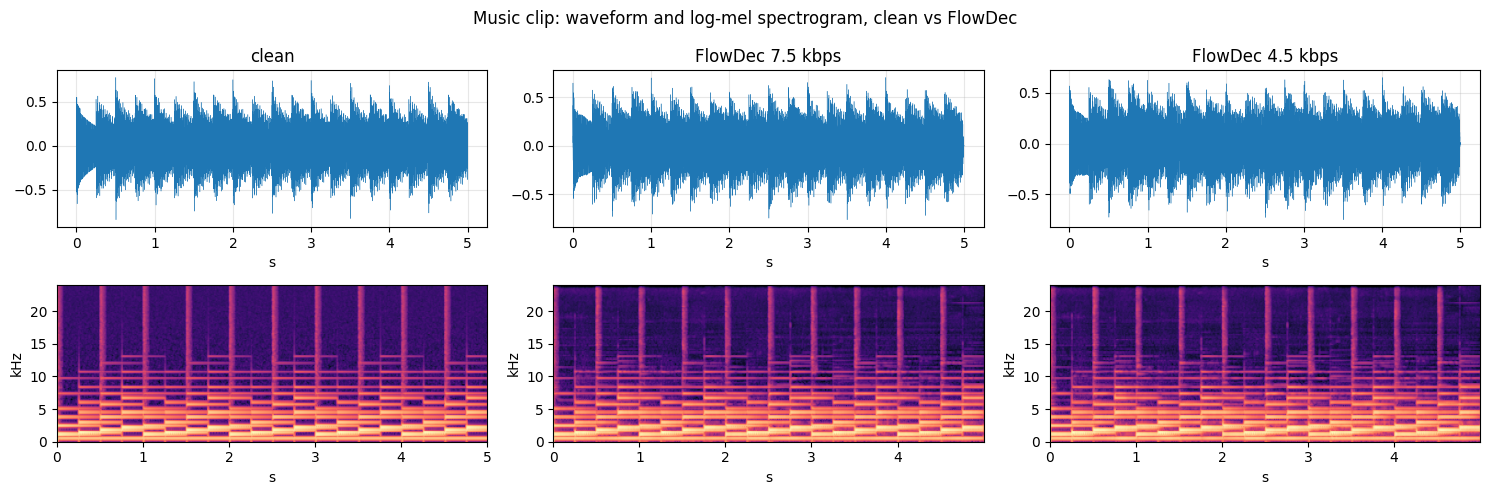

In [5]:
path = ROOT / "data" / "custom" / "music" / "music_0.wav"
src = load_wav48k(path)[:, :5 * SR]
ref = to_numpy_mono(src)

outs = {}
for nq in (10, 6):
    kbps = NQ_TO_KBPS_75M[nq]
    outs[kbps] = to_numpy_mono(full_flowdec(bundle, src, nq=nq, n_steps=3, seed=SEED)["flowdec"])

fig, axes = plt.subplots(2, 3, figsize=(15, 5))
panels = [("clean", ref), ("FlowDec 7.5 kbps", outs[7.5]), ("FlowDec 4.5 kbps", outs[4.5])]
for j, (title, wav) in enumerate(panels):
    axes[0][j].plot(np.arange(len(wav)) / SR, wav, lw=0.3)
    axes[0][j].set_title(title); axes[0][j].set_xlabel("s"); axes[0][j].grid(alpha=0.3)
    mel = mel_spectrogram(wav, sr=SR)
    axes[1][j].imshow(mel, origin="lower", aspect="auto", cmap="magma", extent=[0, len(wav)/SR, 0, SR/2000])
    axes[1][j].set_xlabel("s"); axes[1][j].set_ylabel("kHz")
fig.suptitle("Music clip: waveform and log-mel spectrogram, clean vs FlowDec")
fig.tight_layout(); plt.show()

### 3b. Classical baselines: Opus (ffmpeg) and Griffin-Lim

Both transmit the same audio at a comparable low rate: Opus at 4.5 / 7.5 kbit/s and
Griffin-Lim from a rate-matched (~7.7 kbit/s) mel magnitude spectrogram with iterative
phase recovery. Metrics are computed exactly as for FlowDec.

In [6]:
rows = []
for name, est in [
    ("FlowDec 7.5", outs[7.5]),
    ("FlowDec 4.5", outs[4.5]),
    ("Opus 7.5", opus_roundtrip(src, 7.5)),
    ("Opus 4.5", opus_roundtrip(src, 4.5)),
    ("Griffin-Lim", griffin_lim_roundtrip(src)),
]:
    m = metrics_for_pair(ref[: min(len(ref), len(est))], est[: min(len(ref), len(est))])
    rows.append((name, m["si_sdr"], m["fwssnr"], m["logspec_mse"]))

print(f"{'method':>12} | {'SI-SDR':>7} | {'fwSSNR':>7} | {'logSpecMSE':>10}")
for name, s, f, l in rows:
    print(f"{name:>12} | {s:7.2f} | {f:7.2f} | {l:10.1f}")
print(f"\nGriffin-Lim nominal rate: {griffin_lim_mel_kbps():.1f} kbit/s")

      method |  SI-SDR |  fwSSNR | logSpecMSE
 FlowDec 7.5 |   14.56 |   20.04 |       97.2
 FlowDec 4.5 |   11.84 |   16.93 |      105.0
    Opus 7.5 |    2.33 |    7.79 |     2274.2
    Opus 4.5 |    0.05 |    6.60 |     2297.1
 Griffin-Lim |  -45.64 |    2.75 |      171.2

Griffin-Lim nominal rate: 7.7 kbit/s


### 3c. Perceptual metric — Frechet Audio Distance (CLAP-laion-audio)

FAD compares the distribution of CLAP audio embeddings of the reconstructions with the
clean reference. Lower is better and, unlike SI-SDR, it tracks perceptual quality.

In [7]:
fad = FAD(sample_rate=SR)
clips = [to_numpy_mono(load_wav48k(p)[:, :5 * SR]) for _, p in custom]
ref_emb = fad.embed(clips)

def fad_of(fn):
    return fad.score_from_embeddings(ref_emb, fad.embed([to_numpy_mono(fn) for _, p in custom]))

def _flow(p, kbps):
    return full_flowdec(bundle, load_wav48k(p)[:, :5 * SR], nq={7.5: 10, 4.5: 6}[kbps], n_steps=3, seed=SEED)["flowdec"]

print("FAD x100 on our custom set (lower is better):")
for label, fn in [
    ("FlowDec 7.5", lambda p: _flow(p, 7.5)),
    ("FlowDec 4.5", lambda p: _flow(p, 4.5)),
    ("Opus 7.5", lambda p: torch.from_numpy(opus_roundtrip(load_wav48k(p)[:, :5*SR], 7.5)).unsqueeze(0)),
    ("Opus 4.5", lambda p: torch.from_numpy(opus_roundtrip(load_wav48k(p)[:, :5*SR], 4.5)).unsqueeze(0)),
    ("Griffin-Lim", lambda p: torch.from_numpy(griffin_lim_roundtrip(load_wav48k(p)[:, :5*SR])).unsqueeze(0)),
]:
    wavs = [to_numpy_mono(fn(p)) for _, p in custom]
    print(f"  {label:>12}: {fad.score_from_embeddings(ref_emb, fad.embed(wavs)) * 100:6.1f}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Load our best checkpoint in the paper.
The checkpoint is already downloaded
Load Checkpoint...


FAD x100 on our custom set (lower is better):


Your vector field does not have `nn.Parameters` to optimize.


Your vector field does not have `nn.Parameters` to optimize.


... (11 outputs left out)

   FlowDec 4.5:   26.0


      Opus 7.5:   78.7


      Opus 4.5:   99.2


   Griffin-Lim:  100.0


## 4. Solver-step (NFE) ablation

With the `midpoint` solver NFE = 2·N. FlowDec stays usable at NFE = 4–6, which is the
paper's central efficiency claim (ScoreDec needs ~60).

In [8]:
path = ROOT / "data" / "custom" / "music" / "music_0.wav"
src = load_wav48k(path)[:, :4 * SR]
ref = to_numpy_mono(src)
print(f"{'NFE':>4} | {'SI-SDR':>7} | {'fwSSNR':>7} | {'logSpecMSE':>10}")
for n_steps, nfe in [(1, 2), (2, 4), (3, 6), (25, 50)]:
    est = to_numpy_mono(full_flowdec(bundle, src, nq=10, n_steps=n_steps, seed=SEED)["flowdec"])
    m = metrics_for_pair(ref[: len(est)], est[: len(ref)])
    print(f"{nfe:>4} | {m['si_sdr']:7.2f} | {m['fwssnr']:7.2f} | {m['logspec_mse']:10.1f}")

 NFE |  SI-SDR |  fwSSNR | logSpecMSE


Your vector field does not have `nn.Parameters` to optimize.


   2 |   14.94 |   16.83 |      471.3


Your vector field does not have `nn.Parameters` to optimize.


   4 |   15.15 |   19.96 |       88.6


Your vector field does not have `nn.Parameters` to optimize.


   6 |   14.86 |   20.31 |       74.2


Your vector field does not have `nn.Parameters` to optimize.


  50 |   14.66 |   20.36 |       68.6


## 5. Demo assets — listen

Saved demo WAVs from `results/demo/` (input vs FlowDec vs Opus).

In [9]:
demo = ROOT / "results" / "demo"
for name in ["music_music_0_input.wav", "music_music_0_flowdec_7.5kbps.wav",
             "music_music_0_flowdec_4.5kbps.wav", "music_music_0_opus_4.5kbps.wav"]:
    p = demo / name
    if p.is_file():
        print(name)
        display(Audio(str(p)))

music_music_0_input.wav


music_music_0_flowdec_7.5kbps.wav


music_music_0_flowdec_4.5kbps.wav


music_music_0_opus_4.5kbps.wav


## 6. Conclusion

FlowDec reproduces the authors' outputs on their own audio, and on our custom 48 kHz data
it is clearly better than rate-matched classical baselines on the perceptual (FAD) axis and
strong on SI-SDR / fwSSNR, while remaining usable at NFE = 4–6. The main practical caveats
are the CC-BY-NC licence, the non-causal (non-streaming) design, and the fact that on Apple
Silicon MPS the fast path trades away quality, so CPU is used for the reported numbers.